# Notebook exploratorio para predecir el valor MIC de 82 contigs plasmidicos distintos apartir de sus vectores topológicos

## Librerías

In [31]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt

## Datos

### Vectores topologicos

In [2]:
df_Optimizado = pd.read_csv("/files2/gerardo/KmerTopology/data/processed/optimized_pipeline/vectors_topB_escherichia.csv", header=None)
vect_E = df_Optimizado.to_numpy()

### Accesion y cruza con su estado y MIC

In [3]:
#Accesion (id del genoma)
id_column="name"

df_ids = pd.read_csv("/files2/gerardo/KmerTopology/data/processed/optimized_pipeline/escherichia_plasmid_82.csv")

ids = df_ids[id_column].astype(str).tolist()

In [4]:
# Manifiesto, accesion + fenotipo + MIC
id_column = "accession"
label_column = "phenotype"
mic_column = "mic"

df_manifest = pd.read_csv("/files2/gerardo/KmerTopology/data/processed/selected_genomes/plasmid_manifest.csv", dtype=str)

# Solo el fenotipo decide que accessions se usan (igual que antes); el MIC
# puede faltar en algunos genomas y no los descartamos solo por eso.
df_manifest = df_manifest.dropna(subset=[id_column, label_column])

label_lookup = dict(zip(df_manifest[id_column].astype(str), df_manifest[label_column].astype(str)))


def _to_float_or_nan(value):
    try:
        if value is None or str(value).strip() == "":
            return np.nan
        return float(value)
    except (TypeError, ValueError):
        return np.nan


# MIC como float; vacio/NaN/no-numerico se guarda como np.nan (el accession
# conserva su fenotipo, solo no tendra MIC en las graficas que lo usen)
if mic_column in df_manifest.columns:
    mic_lookup = {
        accession: _to_float_or_nan(mic)
        for accession, mic in zip(df_manifest[id_column].astype(str), df_manifest[mic_column])
    }
else:
    print(f"Aviso: el manifiesto no tiene columna '{mic_column}', todos los MIC quedaran como NaN")
    mic_lookup = {}

In [5]:
if len(ids) == len(vect_E):
    print("Misma cantidad de datos")

Misma cantidad de datos


In [6]:
keep_idx = []
ids_sin_label = []

for i, accession in enumerate(ids):
    if accession in label_lookup:
        keep_idx.append(i)
    else:
        print(accession)
        ids_sin_label.append(accession)

X = vect_E[keep_idx]
ids_usados = [ids[i] for i in keep_idx]
labels_usados = np.array([label_lookup[a] for a in ids_usados])

# MIC alineado al mismo orden que ids_usados / labels_usados; np.nan donde
# el accession no tenga MIC en el manifiesto
mic_usados = np.array([mic_lookup.get(a, np.nan) for a in ids_usados], dtype=float)

n_sin_mic = int(np.isnan(mic_usados).sum())
print(f"Accessions con fenotipo: {len(ids_usados)}")
print(f"Accessions sin MIC (quedan como NaN, se excluyen solo de las graficas de MIC): {n_sin_mic}")

# return X, ids_usados, labels_usados, mic_usados, ids_sin_label

Accessions con fenotipo: 82
Accessions sin MIC (quedan como NaN, se excluyen solo de las graficas de MIC): 0


In [7]:
print(labels_usados)
print(mic_usados)

['susceptible' 'susceptible' 'susceptible' 'susceptible' 'resistant'
 'resistant' 'resistant' 'susceptible' 'susceptible' 'resistant'
 'resistant' 'susceptible' 'susceptible' 'intermediate' 'susceptible'
 'susceptible' 'resistant' 'resistant' 'resistant' 'resistant'
 'intermediate' 'resistant' 'resistant' 'resistant' 'resistant'
 'susceptible' 'susceptible' 'resistant' 'susceptible' 'susceptible'
 'susceptible' 'susceptible' 'resistant' 'resistant' 'resistant'
 'intermediate' 'susceptible' 'resistant' 'susceptible' 'resistant'
 'resistant' 'susceptible' 'susceptible' 'resistant' 'susceptible'
 'susceptible' 'intermediate' 'susceptible' 'resistant' 'resistant'
 'susceptible' 'susceptible' 'susceptible' 'resistant' 'resistant'
 'resistant' 'intermediate' 'resistant' 'susceptible' 'susceptible'
 'susceptible' 'susceptible' 'susceptible' 'susceptible' 'resistant'
 'susceptible' 'resistant' 'resistant' 'susceptible' 'susceptible'
 'resistant' 'intermediate' 'susceptible' 'resistant' 'suscep

# Random Forest

## Dividimos los datos

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    vect_E, mic_usados,
    test_size=0.2,
    random_state=42
)

## Modelo

In [26]:
modelo = RandomForestRegressor(
    n_estimators=50,
    random_state=42
)

In [27]:
modelo.fit(X_train, y_train)

RandomForestRegressor(n_estimators=50, random_state=42)

## Acuracy

In [28]:
print("MSE:", mean_squared_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

MSE: 236.94508367529414
R²: 0.007251338011826869


## Visualización

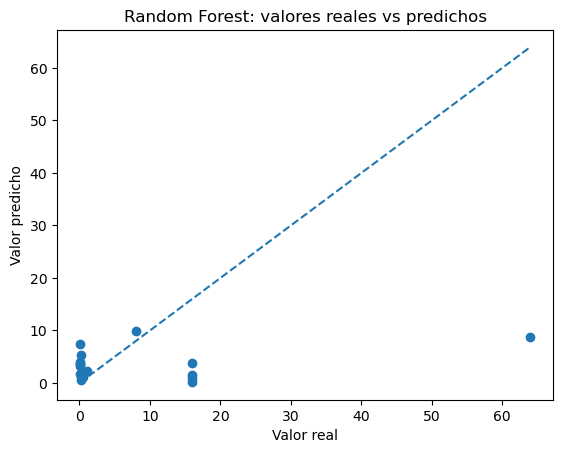

In [29]:
plt.scatter(y_test, y_pred)

plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Random Forest: valores reales vs predichos")

# Línea ideal y = x
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

## Cross Validation

In [30]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    modelo,
    vect_E,
    mic_usados,
    cv=cv,
    scoring="r2"
)

print(scores)
print("R² promedio:", scores.mean())

[ 0.11063293 -0.05466931 -4.1332815  -1.37078771 -1.01197719]
R² promedio: -1.2920165573011215


## Para predecir la etiqueta en lugar del MIC

Accuracy: 0.5294117647058824

Reporte de clasificación:
              precision    recall  f1-score   support

intermediate       0.00      0.00      0.00         1
   resistant       0.50      0.29      0.36         7
 susceptible       0.58      0.78      0.67         9

    accuracy                           0.53        17
   macro avg       0.36      0.35      0.34        17
weighted avg       0.51      0.53      0.50        17



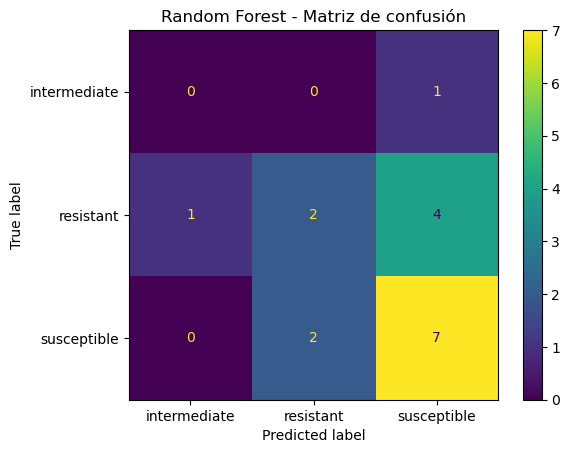

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
# Train / test
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    vect_E,
    labels_usados,
    test_size=0.2,
    random_state=42,
    stratify=labels_usados
)

modelo_rf_clf = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

modelo_rf_clf.fit(X_train, y_train)

y_pred = modelo_rf_clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))


# -------------------------
# Matriz de confusión
# -------------------------
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=modelo_rf_clf.classes_
)

disp.plot()

plt.title("Random Forest - Matriz de confusión")
plt.show()

## knn

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    vect_E,
    mic_usados,
    test_size=0.2,
    random_state=42
)

modelo_knn = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=1)
)

modelo_knn.fit(X_train, y_train)

y_pred = modelo_knn.predict(X_test)

print("MSE:", mean_squared_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

MSE: 262.82964558823534
R²: -0.10119937895023945


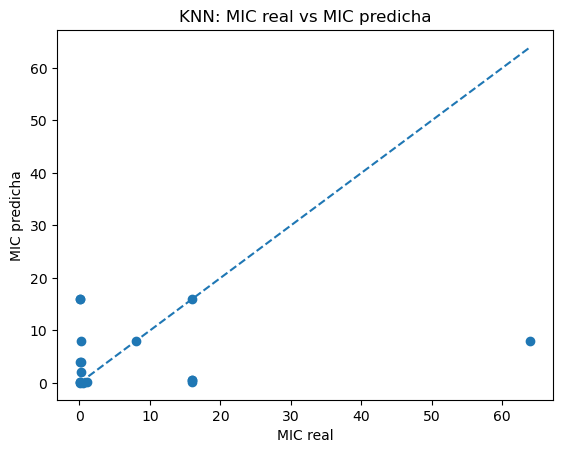

In [44]:
# Gráfica
# -------------------------
plt.scatter(y_test, y_pred)

plt.xlabel("MIC real")
plt.ylabel("MIC predicha")
plt.title("KNN: MIC real vs MIC predicha")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [45]:
# Cross-validation
# -------------------------
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    modelo_knn,
    vect_E,
    mic_usados,
    cv=cv,
    scoring="r2"
)

print("R² por fold:", scores)
print("R² promedio:", scores.mean())

R² por fold: [-0.10119938 -0.41213636 -2.00469443 -0.72233232 -1.06790615]
R² promedio: -0.8616537254607696


In [47]:
import numpy as np
import pandas as pd

df_Optimizado = pd.read_csv("/files2/gerardo/KmerTopology/data/processed/complete_genomes/vectors_topB.csv", header=None)
vect_E = df_Optimizado.to_numpy()

# Accesion (id del genoma) en el archivo de vectores
df_ids = pd.read_csv("/files2/gerardo/KmerTopology/data/processed/complete_genomes/complete_genomes.csv")
ids = df_ids["name"].astype(str).tolist()

# Metadata original (de donde sale el manifiesto)
metadata_path = "/files2/gerardo/KmerTopology/data/raw/metadata/pangenome.metadata.csv"
id_column = "accession"      # AJUSTAR si se llama distinto en la metadata
label_column = "phenotype"   # AJUSTAR
mic_column = "mic"           # AJUSTAR

# Si la metadata trae varios antibioticos (una fila por accession x antibiotico),
# filtra aqui el que usa tu manifiesto. Deja en None si no aplica.
antibiotic_column = None     # p.ej. "antibiotic"
antibiotic_value = None      # p.ej. "ciprofloxacin"

df_meta = pd.read_csv(metadata_path, dtype=str)

faltantes = [c for c in (id_column, label_column) if c not in df_meta.columns]
if faltantes:
    raise KeyError(f"Columnas no encontradas en la metadata: {faltantes}\n"
                   f"Columnas disponibles: {list(df_meta.columns)}")

if antibiotic_column is not None:
    df_meta = df_meta[df_meta[antibiotic_column] == antibiotic_value]

# Solo el fenotipo decide que accessions se usan; el MIC puede faltar
df_meta = df_meta.dropna(subset=[id_column, label_column])

# Revisar accessions duplicados (misma accession con fenotipos distintos = ambiguo)
dup = df_meta[df_meta.duplicated(subset=id_column, keep=False)]
if len(dup) > 0:
    n_conflicto = int((dup.groupby(id_column)[label_column].nunique() > 1).sum())
    print(f"Aviso: {dup[id_column].nunique()} accessions repetidos en la metadata "
          f"({n_conflicto} con fenotipos contradictorios). Se conserva la primera fila.")
    df_meta = df_meta.drop_duplicates(subset=id_column, keep="first")

label_lookup = dict(zip(df_meta[id_column].astype(str), df_meta[label_column].astype(str)))


def _to_float_or_nan(value):
    try:
        if value is None or str(value).strip() == "":
            return np.nan
        return float(value)
    except (TypeError, ValueError):
        return np.nan


if mic_column in df_meta.columns:
    mic_lookup = {
        accession: _to_float_or_nan(mic)
        for accession, mic in zip(df_meta[id_column].astype(str), df_meta[mic_column])
    }
else:
    print(f"Aviso: la metadata no tiene columna '{mic_column}', todos los MIC quedaran como NaN")
    mic_lookup = {}

keep_idx = []
ids_sin_label = []

for i, accession in enumerate(ids):
    if accession in label_lookup:
        keep_idx.append(i)
    else:
        print(accession)
        ids_sin_label.append(accession)

X = vect_E[keep_idx]
ids_usados = [ids[i] for i in keep_idx]
labels_usados = np.array([label_lookup[a] for a in ids_usados])
mic_usados = np.array([mic_lookup.get(a, np.nan) for a in ids_usados], dtype=float)

n_sin_mic = int(np.isnan(mic_usados).sum())
print(f"Accessions con fenotipo: {len(ids_usados)}")
print(f"Accessions sin MIC (quedan como NaN, se excluyen solo de las graficas de MIC): {n_sin_mic}")

Aviso: 5121 accessions repetidos en la metadata (2457 con fenotipos contradictorios). Se conserva la primera fila.
GCA_037951045.1.fna
GCA_003073795.1.fna
GCA_039699835.1.fna
GCA_003074115.1.fna
GCA_003288335.1.fna
GCA_037199675.2.fna
GCA_032629165.2.fna
GCA_037046245.2.fna
GCA_002968585.1.fna
GCA_037809465.1.fna
GCA_000775955.1.fna
GCA_037202005.1.fna
GCA_030253475.1.fna
GCA_000807395.2.fna
GCA_040256175.1.fna
GCA_000626615.3.fna
GCA_021496255.1.fna
GCA_009455505.1.fna
GCA_000368185.1.fna
GCA_003071645.1.fna
GCA_003194245.1.fna
GCA_003193745.1.fna
GCA_002948925.1.fna
GCA_020540925.1.fna
GCA_003073735.1.fna
GCA_013343375.1.fna
GCA_003324295.1.fna
GCA_040114725.1.fna
GCA_041519645.1.fna
GCA_039134645.1.fna
GCA_002085525.1.fna
GCA_005326725.2.fna
GCA_002968515.1.fna
GCA_004116595.1.fna
GCA_019269335.1.fna
GCA_030444635.1.fna
GCA_001562175.1.fna
GCA_040234425.1.fna
GCA_043235915.1.fna
GCA_007765995.2.fna
GCA_009176765.1.fna
GCA_013375855.1.fna
GCA_037482185.1.fna
GCA_003010695.1.fna
GCA_0